# 13 · Capstone: Customer Support Agent  🔴 Expert

Everything together in one realistic app for an online store, **TechMart**:

| Feature | Concept (notebook) |
|---|---|
| Triage each message (order issue / question / off-topic) | structured output + routing (08) |
| ReAct agent with tools: orders, FAQ, refunds | tools & agents (04) |
| Refunds need **human supervisor approval** | `interrupt()` in a tool (06) |
| Customer id passed securely, never by the model | runtime context + `ToolRuntime` (11) |
| Customer profile (name, tier) | long-term Store (11) |
| Multi-turn conversation | checkpointer (05) |
| Live progress | streaming (07) |

In [1]:
from helpers import get_llm, show_graph, print_messages

llm = get_llm()   # ChatAnthropic -> Claude, key read from CLAUDE_KEY in .env

## 1. Fake backend: orders, FAQ, customer profiles

In [2]:
ORDERS = {
    "A1001": {"customer_id": "cust-42", "item": "Wireless Headphones", "price_inr": 2999, "status": "delivered", "delivered_days_ago": 5},
    "A1002": {"customer_id": "cust-42", "item": "USB-C Charger",       "price_inr": 899,  "status": "shipped",   "delivered_days_ago": None},
    "B2001": {"customer_id": "cust-77", "item": "Smart Watch",         "price_inr": 7999, "status": "delivered", "delivered_days_ago": 12},
}
FAQ = {
    "return":   "Refunds are accepted within 30 days of delivery for defective or unused items.",
    "shipping": "Standard shipping takes 3-5 business days; express (1-2 days) costs ₹99.",
    "warranty": "All electronics include a 1-year manufacturer warranty.",
}

from langgraph.store.memory import InMemoryStore
store = InMemoryStore()
store.put(("customers",), "cust-42", {"name": "Priya", "tier": "Gold", "since": 2021})
store.put(("customers",), "cust-77", {"name": "Rahul", "tier": "Silver", "since": 2024})

## 2. Tools

`ToolRuntime` is injected by LangGraph and **hidden from the model**: the model can't fake the customer id,
so a customer can never read or refund someone else's order.

In [3]:
import json
from dataclasses import dataclass
from langchain.tools import tool, ToolRuntime
from langgraph.types import interrupt

@dataclass
class SupportContext:
    customer_id: str

def _own_order(order_id: str, customer_id: str):
    order = ORDERS.get(order_id.upper())
    return order if order and order["customer_id"] == customer_id else None

@tool
def lookup_order(order_id: str, runtime: ToolRuntime[SupportContext]) -> str:
    """Look up an order's item, price, status and days since delivery."""
    order = _own_order(order_id, runtime.context.customer_id)
    return json.dumps({k: v for k, v in order.items() if k != "customer_id"}) if order else "Order not found for this customer."

@tool
def search_faq(topic: str) -> str:
    """Search store policies. Topics: return, shipping, warranty."""
    hits = [text for key, text in FAQ.items() if key in topic.lower()]
    return "\n".join(hits) or "No policy found. Available topics: " + ", ".join(FAQ)

@tool
def issue_refund(order_id: str, reason: str, runtime: ToolRuntime[SupportContext]) -> str:
    """Refund an order. Only for eligible orders (delivered within 30 days).
    Calling this automatically sends the request to a human supervisor and waits for their decision."""
    order = _own_order(order_id, runtime.context.customer_id)
    if not order:
        return "Order not found for this customer."
    decision = interrupt({"type": "refund_approval", "order_id": order_id, "item": order["item"],
                          "amount_inr": order["price_inr"], "reason": reason})
    if decision.get("approved"):
        order["status"] = "refunded"
        return f"Supervisor APPROVED. Refund of ₹{order['price_inr']} issued for {order_id}. Reference RF-{order_id}."
    return f"Refund declined by supervisor: {decision.get('note', 'no reason given')}"

tools = [lookup_order, search_faq, issue_refund]

## 3. The graph: triage → (decline | agent ⇄ tools)

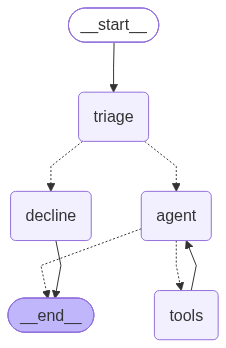

In [4]:
from typing import Literal
from pydantic import BaseModel, Field
from langchain_core.messages import SystemMessage, AIMessage
from langgraph.graph import StateGraph, MessagesState, START, END
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.runtime import Runtime
from langgraph.checkpoint.memory import InMemorySaver
from helpers import get_llm

class Triage(BaseModel):
    category: Literal["order_issue", "general_question", "off_topic"]
    summary: str = Field(description="One-line summary of what the customer wants")

triage_llm = get_llm(effort="low").with_structured_output(Triage, method="json_schema")
agent_llm = llm.bind_tools(tools)

class SupportState(MessagesState):
    category: str
    summary: str

def triage(state: SupportState):
    t = triage_llm.invoke("Classify this message to an electronics store's support desk:\n" + state["messages"][-1].text)
    print(f"🏷️  triage: {t.category} | {t.summary}")
    return {"category": t.category, "summary": t.summary}

def route(state: SupportState) -> Literal["agent", "decline"]:
    return "decline" if state["category"] == "off_topic" else "agent"

def decline(state: SupportState):
    return {"messages": [AIMessage("I'm TechMart's support assistant, so I can only help with orders, "
                                   "shipping, returns and warranties. Is there anything like that I can do for you?")]}

def agent(state: SupportState, runtime: Runtime[SupportContext]):
    profile = runtime.store.get(("customers",), runtime.context.customer_id).value
    system = SystemMessage(
        f"You are TechMart's friendly support agent. Customer: {profile['name']} ({profile['tier']} member since {profile['since']}).\n"
        f"Current request: {state['summary']}\n"
        "Rules: look up orders before acting; check the return policy before refunds; only refund eligible orders; "
        "never invent order details; keep replies under 80 words.")
    return {"messages": [agent_llm.invoke([system] + state["messages"])]}

b = StateGraph(SupportState, context_schema=SupportContext)
b.add_node(triage); b.add_node(decline); b.add_node(agent)
b.add_node("tools", ToolNode(tools, handle_tool_errors=True))
b.add_edge(START, "triage")
b.add_conditional_edges("triage", route)
b.add_conditional_edges("agent", tools_condition)
b.add_edge("tools", "agent")
b.add_edge("decline", END)

support_bot = b.compile(checkpointer=InMemorySaver(), store=store)
show_graph(support_bot)

## 4. A streaming chat helper

Streams node updates, prints tool activity, and surfaces interrupts that need a human supervisor.

In [5]:
from langgraph.types import Command

def run(payload, thread_id="ticket-1", customer_id="cust-42"):
    config = {"configurable": {"thread_id": thread_id}}
    for update in support_bot.stream(payload, config, context=SupportContext(customer_id), stream_mode="updates"):
        for node, changes in update.items():
            if node == "__interrupt__":
                req = changes[0].value
                print(f"⏸️  SUPERVISOR APPROVAL NEEDED: refund ₹{req['amount_inr']} for {req['item']} "
                      f"({req['order_id']}), reason: {req['reason']}")
                continue
            for m in (changes or {}).get("messages", []):
                for c in getattr(m, "tool_calls", None) or []:
                    print(f"🔧 {c['name']}({c['args']})")
                if m.type == "tool":
                    print(f"📦 {m.text[:120]}")
                elif m.type == "ai" and m.text:
                    print(f"🤖 {m.text}")

def chat(text, **kw):
    print(f"\n🧑 {text}")
    run({"messages": [("user", text)]}, **kw)

## 5. Demo conversation (customer Priya, `cust-42`)

In [6]:
chat("Hi! What's your return policy?")


🧑 Hi! What's your return policy?


🏷️  triage: general_question | Customer is asking about the store's return policy.


🔧 search_faq({'topic': 'return'})
📦 Refunds are accepted within 30 days of delivery for defective or unused items.


🤖 Hi Priya! You can return items within 30 days of delivery if they're defective or unused, and you'll get a refund.

Do you have an order you'd like to return? Send me the order number and I'll check whether it qualifies.


In [7]:
chat("My headphones from order A1001 stopped working after 5 days. I'd like a refund please.")


🧑 My headphones from order A1001 stopped working after 5 days. I'd like a refund please.


🏷️  triage: order_issue | Customer requests a refund for headphones from order A1001 that stopped working after 5 days.


🔧 lookup_order({'order_id': 'A1001'})
📦 {"item": "Wireless Headphones", "price_inr": 2999, "status": "delivered", "delivered_days_ago": 5}


🔧 issue_refund({'order_id': 'A1001', 'reason': 'Defective: wireless headphones stopped working 5 days after delivery'})
⏸️  SUPERVISOR APPROVAL NEEDED: refund ₹2999 for Wireless Headphones (A1001), reason: Defective: wireless headphones stopped working 5 days after delivery


The run is **paused** inside `issue_refund`. A supervisor reviews and approves:

In [8]:
run(Command(resume={"approved": True, "note": "Defective within policy window"}))

📦 Supervisor APPROVED. Refund of ₹2999 issued for A1001. Reference RF-A1001.


🤖 I'm sorry your headphones stopped working, Priya. Your order A1001 (Wireless Headphones) was delivered 5 days ago, so it qualifies for a refund.

A supervisor approved it, and I've issued a refund of ₹2,999. Your reference number is **RF-A1001**.

Is there anything else I can help with?


In [9]:
chat("Can you also refund order B2001?")   # belongs to another customer -> blocked by ToolRuntime


🧑 Can you also refund order B2001?


🏷️  triage: order_issue | Customer requests a refund for order B2001.


🔧 lookup_order({'order_id': 'B2001'})
📦 Order not found for this customer.


🤖 I couldn't find order **B2001** on your account, Priya, so I can't refund it yet.

Could you check the order number? It's in your confirmation email or under "My Orders." If the order was placed from another account, please tell me which one. Once I find it, I'll check whether it qualifies for a refund.


In [10]:
chat("Write me a poem about cats.")         # off-topic -> polite decline, no agent call


🧑 Write me a poem about cats.


🏷️  triage: off_topic | Customer requests a poem about cats, which is unrelated to the electronics store's products or orders.
🤖 I'm TechMart's support assistant, so I can only help with orders, shipping, returns and warranties. Is there anything like that I can do for you?


In [11]:
chat("Thanks! Can you summarize everything you did for me today?")


🧑 Thanks! Can you summarize everything you did for me today?


🏷️  triage: general_question | Customer thanks support and asks for a summary of the help provided during today's interaction.


🤖 You're welcome, Priya! Here's what we did today:

1. **Return policy:** You can get a refund within 30 days of delivery for defective or unused items.
2. **Order A1001 (Wireless Headphones):** A supervisor approved your refund of ₹2,999. Your reference number is **RF-A1001**.
3. **Order B2001:** I couldn't find this order on your account, so there's no refund yet. Send me the correct order number and I'll check it.

Have a great day!


## 6. Inspect the final state

In [12]:
state = support_bot.get_state({"configurable": {"thread_id": "ticket-1"}})
print("messages in thread:", len(state.values["messages"]))
print("last triage:", state.values["category"], "|", state.values["summary"])
print("order A1001 status:", ORDERS["A1001"]["status"])

messages in thread: 18
last triage: general_question | Customer thanks support and asks for a summary of the help provided during today's interaction.
order A1001 status: refunded


## 🎓 Where to go from here
* Replace fake data with a real DB / APIs; `PostgresSaver` + `PostgresStore` for persistence.
* Add a `save_customer_note` tool that writes to the Store (episodic memory).
* Split into a **supervisor + specialists** (billing, tech support) as in notebook 10.
* Serve it with `langgraph dev`, trace with LangSmith, add tests with fake models (notebook 12).

**Congratulations, you've gone from a single LLM call to a production-style agent! 🎉**